# 04. Эксперименты и улучшение решения

**Автор / команда:** Бахтибеков Артур, Макаров Ярослав · КМБО-24-24  
**Название проекта:** Классификация степени зрелости фруктов по изображениям  
**Датасет:** Fruits-360, авокадо (unripe / ripe / overripe)  
**Данные и baseline:** разбиение из ноутбука 02; baseline из ноутбука 03 — MobileNetV2 (transfer learning), val accuracy 0.996, macro-F1 0.996, 2 ошибки из 459

Цель — воспроизвести baseline, проанализировать его ошибки, сформулировать и проверить гипотезы улучшения по единому заранее фиксированному правилу сравнения, выбрать лучший вариант и сохранить его без повторного обучения.

## 1. Исходное решение и правила сравнения

Исходное решение — baseline из ноутбука 03: MobileNetV2, предобученная на ImageNet, с замороженной базовой частью и новой 3-классовой головой; обучение только на train (2600 изображений), EarlyStopping по val_accuracy.

Во всех опытах ниже используется одна и та же validation — то же разбиение, что в ноутбуках 02–03 (85/15, random_state=42, стратификация по классам). Модели обучаются только по train. Test не используется и остаётся для итоговой проверки при финальной проверке.

**Основная метрика и правило выбора:** основная метрика — macro-F1 на validation (выбрана в ноутбуке 03 из-за дисбаланса классов 23 / 30 / 47%), направление — максимум. Дополнительная метрика (tie-break) — accuracy. При равенстве обеих метрик сохраняем более ранний вариант (baseline).

**Остальные условия, одинаковые для всех опытов:** один конвейер входа (resize 224×224, rescale 1/255 внутри модели), один и тот же RANDOM_STATE=42, batch 32, EarlyStopping по val_accuracy с восстановлением лучших весов, оптимизатор Adam. Отличаться от baseline может только то изменение, которое описано в проверяемой гипотезе. Разметку не меняем: ошибки не «исправляются» правкой данных ради улучшения метрик.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight

print('TensorFlow:', tf.__version__)
RANDOM_STATE = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
CLASS_NAMES = ['unripe', 'ripe', 'overripe']
LABEL_TO_INT = {name: i for i, name in enumerate(CLASS_NAMES)}
primary_metric = 'macro_f1'      # основная метрика (дисбаланс классов)
tie_break_metric = 'accuracy'    # дополнительная метрика

TensorFlow: 2.21.0


In [2]:
# Разбиение воспроизводится побитово той же логикой, что в заданиях 02-03:
# тот же порядок обхода, дедупликация sha256 и random_state=42.
from sklearn.model_selection import train_test_split
import hashlib

DATA_DIR = Path('/kaggle/input/fruits/fruits-360_100x100/fruits-360')
if not DATA_DIR.exists():
    for cand in Path('/kaggle/input').rglob('fruits-360'):
        if cand.is_dir():
            DATA_DIR = cand
            break
print('Датасет найден:', DATA_DIR, DATA_DIR.exists())

CLASS_MAP = {
    'Avocado Green 1': 'unripe',
    'Avocado 1': 'ripe',
    'Avocado 2': 'ripe',
    'Avocado Black 1': 'overripe',
    'Avocado Black 2': 'overripe',
}
records = []
for part_name in ['Training', 'Test']:
    for class_name, ripeness in CLASS_MAP.items():
        for image_path in sorted((DATA_DIR / part_name / class_name).glob('*.jpg')):
            records.append({'image_id': f'{class_name}/{image_path.stem}',
                            'path': str(image_path), 'label': ripeness,
                            'official_part': part_name, 'class_name': class_name})
full_df = pd.DataFrame(records)

full_df['file_hash'] = full_df['path'].map(
    lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest())
dup_mask = full_df.duplicated(subset=['file_hash'], keep='first')
print('Точных копий файлов:', int(dup_mask.sum()))
full_df = full_df.loc[~dup_mask].reset_index(drop=True)

training_df = full_df[full_df['official_part'] == 'Training'].copy()
test_df = full_df[full_df['official_part'] == 'Test'].copy()
train_df, val_df = train_test_split(
    training_df, test_size=0.15, random_state=42,
    stratify=training_df['label'])

train_int = train_df['label'].map(LABEL_TO_INT).to_numpy()
val_true = val_df['label'].map(LABEL_TO_INT).to_numpy()
for name, part in [('train', train_df), ('validation', val_df), ('test', test_df)]:
    print(f"{name}: {len(part)} изображений, распределение меток:",
          part['label'].value_counts().to_dict())

Датасет найден: /kaggle/input/datasets/moltean/fruits/fruits-360_100x100/fruits-360 True
Точных копий файлов: 1
train: 2600 изображений, распределение меток: {'overripe': 1224, 'ripe': 779, 'unripe': 597}
validation: 459 изображений, распределение меток: {'overripe': 216, 'ripe': 138, 'unripe': 105}
test: 1017 изображений, распределение меток: {'overripe': 477, 'ripe': 309, 'unripe': 231}


In [3]:
# tf.data-конвейер: путь -> изображение -> resize 224x224 -> метка (0=unripe, 1=ripe, 2=overripe)
label_lookup = tf.keras.layers.StringLookup(
    vocabulary=['unripe', 'ripe', 'overripe'], num_oov_indices=0, output_mode='int'
)

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    return image, label_lookup(label)

def make_dataset(df, shuffle=False, batch_size=BATCH_SIZE):
    labels = df['label'].to_numpy().astype(str)
    ds = tf.data.Dataset.from_tensor_slices((df['path'].to_numpy().astype(str), labels))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    if shuffle:
        ds = ds.shuffle(buffer_size=len(df), seed=RANDOM_STATE)
    ds = ds.batch(batch_size).cache().prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, shuffle=True)
val_ds = make_dataset(val_df)

for images, labels in train_ds.take(1):
    print('Батч:', images.shape, images.dtype, 'мин/макс:',
          float(tf.reduce_min(images[0])), float(tf.reduce_max(images[0])))

Батч: (32, 224, 224, 3) <dtype: 'float32'> мин/макс: 0.0 255.0


In [4]:
# Единый конвейер обучения вариантов. Воспроизводит baseline из ноутбука 03
# и добавляет проверяемые изменения: аугментации, class weights, fine-tuning.
def build_variant_model(augmentation='base'):
    inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
    x = tf.keras.layers.RandomFlip('horizontal')(inputs)
    x = tf.keras.layers.RandomRotation(0.1)(x)
    x = tf.keras.layers.RandomZoom(0.1)(x)
    x = tf.keras.layers.Rescaling(1./255)(x)
    if augmentation == 'color':
        # H2: мягкая цветовая аугментация (только в режиме обучения)
        x = tf.keras.layers.RandomContrast(0.2)(x)
    base = tf.keras.applications.MobileNetV2(
        include_top=False, weights='imagenet', input_tensor=x
    )
    base.trainable = False
    x = tf.keras.layers.GlobalAveragePooling2D()(base.output)
    x = tf.keras.layers.Dropout(0.2)(x)
    outputs = tf.keras.layers.Dense(3, activation='softmax')(x)
    model = tf.keras.Model(inputs, outputs)
    return model, base

def train_variant(augmentation='base', class_weight=None, finetune=False,
                  epochs=12, finetune_epochs=5, verbose=2):
    tf.keras.utils.set_random_seed(RANDOM_STATE)
    model, base = build_variant_model(augmentation)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    early = tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy', patience=3, restore_best_weights=True
    )
    cw = None
    if class_weight == 'balanced':
        w = compute_class_weight('balanced', classes=np.arange(3), y=train_int)
        cw = {i: float(x) for i, x in enumerate(w)}
        print('class_weight:', {CLASS_NAMES[i]: round(float(x), 3) for i, x in enumerate(w)})
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                     callbacks=[early], class_weight=cw, verbose=verbose)
    if finetune:
        # H1: размораживаем последние 30 слоёв базовой сети (BatchNorm - в inference-режиме)
        base.trainable = True
        for layer in base.layers[:-30]:
            layer.trainable = False
        for layer in base.layers[-30:]:
            if isinstance(layer, tf.keras.layers.BatchNormalization):
                layer.trainable = False
        model.compile(
            optimizer=tf.keras.optimizers.Adam(1e-5),
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy']
        )
        early_ft = tf.keras.callbacks.EarlyStopping(
            monitor='val_accuracy', patience=2, restore_best_weights=True
        )
        hist_ft = model.fit(train_ds, validation_data=val_ds,
                            epochs=finetune_epochs, callbacks=[early_ft], verbose=verbose)
    return model, hist

## 2. Анализ ошибок baseline

Сначала воспроизводим baseline тем же кодом, что и в ноутбуке 03 (та же архитектура, конвейер и seed; из-за недетерминизма GPU возможны минимальные отличия от запуска в 03). Затем считаем ошибки и смотрим конкретные примеры — какие стадии и в какую сторону путаются.

In [5]:
# Воспроизведение baseline из ноутбука 03.
baseline_model, baseline_history = train_variant()
baseline_prob = baseline_model.predict(val_ds, verbose=0)
baseline_predictions = baseline_prob.argmax(axis=1)
print('Обучено эпох (включая прерванные EarlyStopping):', len(baseline_history.epoch))

/tmp/ipykernel_22/219128635.py:12: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/12
82/82 - 17s - 206ms/step - accuracy: 0.8958 - loss: 0.3135 - val_accuracy: 0.9630 - val_loss: 0.0915
Epoch 2/12
82/82 - 5s - 59ms/step - accuracy: 0.9846 - loss: 0.0713 - val_accuracy: 0.9760 - val_loss: 0.0552
Epoch 3/12
82/82 - 5s - 59ms/step - accuracy: 0.9946 - loss: 0.0375 - val_accuracy: 0.9760 - val_loss: 0.0472
Epoch 4/12
82/82 - 5s - 60ms/step - accuracy: 0.9954 - loss: 0.0276 - val_accuracy: 0.9891 - val_loss: 0.0323
Epoch 5/12
82/82 - 5s - 59ms/step - accuracy: 0.9988 - loss: 0.0199 - val_accuracy: 0.9869 - val_loss: 0.0301
Epoch 6/12
82/82 - 5s - 58ms/step - accuracy: 0.9977 - loss: 0.0175 - val_accuracy: 0.9869 - val_loss: 0.0318
Epoch 7/12
82/82 - 5s - 61ms/step - accuracy: 0.9985 - loss: 0.0143 - val_accuracy: 0.9978 - val_loss: 0.0171
Epoch 8/12
82/82 - 5s - 60ms/step - accuracy: 0.9988 - loss: 0.0130 - val_accuracy: 0.9935 - val_loss: 0.0212
Epoch 9/12
82/82 - 5s - 61ms/step - accuracy: 0.9981 - loss: 0.0126 -

Ошибок baseline на validation: 1 из 459


,,count
true,pred,
unripe,overripe,1


,image_id,true,pred,prob
419,Avocado Green 1/r1_44_100,unripe,overripe,0.575


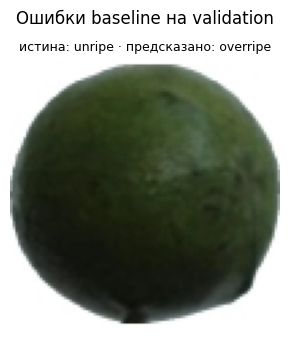

In [6]:
# Сопоставляем ID изображений, истинные ответы и предсказания.
baseline_results = pd.DataFrame({
    'image_id': val_df['image_id'].to_numpy(),
    'path': val_df['path'].to_numpy(),
    'true': val_df['label'].to_numpy(),
    'pred': np.array(CLASS_NAMES)[baseline_predictions],
})
wrong = baseline_results[baseline_results['true'] != baseline_results['pred']].copy()
print('Ошибок baseline на validation:', len(wrong), 'из', len(baseline_results))
if len(wrong):
    pair_counts = wrong.groupby(['true', 'pred']).size().sort_values(ascending=False)
    display(pair_counts.to_frame('count'))
    # уверенность ошибочных предсказаний
    wrong['prob'] = [float(baseline_prob[pos, CLASS_NAMES.index(plab)])
                     for pos, plab in zip(wrong.index, wrong['pred'])]
    display(wrong[['image_id', 'true', 'pred', 'prob']].round(3))

# Показываем ошибочные изображения с истинным и предсказанным ответами.
if len(wrong):
    n = min(4, len(wrong))
    fig, axes = plt.subplots(1, n, figsize=(3 * n, 3.5))
    if n == 1:
        axes = [axes]
    for ax, (_, r) in zip(axes, wrong.head(n).iterrows()):
        ax.imshow(Image.open(r['path']))
        ax.set_title(f"истина: {r['true']} · предсказано: {r['pred']}", fontsize=9)
        ax.axis('off')
    plt.suptitle('Ошибки baseline на validation')
    plt.tight_layout()
    plt.show()

**Наблюдение и ограничение:** в ноутбуке 03 baseline ошибся на 2 изображениях — оба тёмно-зелёных незрелых авокадо (Avocado Green 1), предсказанных как overripe. Воспроизведение выше даёт ошибки того же типа: модель путает тёмную кожуру незрелого плода с чёрной спелой. Это согласуется с анализом яркости из ноутбука 02: распределения соседних стадий перекрываются, и потемнение — не всегда надёжный признак. Это не ошибка разметки, а честные пограничные примеры; менять разметку ради метрик нельзя. Ограничение: ошибок мало (единицы из 459), поэтому запас роста macro-F1 мал (порядка 0.001-0.004). Главный вопрос опыта — не «прыжок метрики», а устойчивость: устраняют ли гипотезы именно ошибки unripe→overripe, не добавляя новых.

## 3. Гипотезы улучшения

План экспериментов фиксируем до запуска. Каждая гипотеза — одно изолированное изменение относительно baseline; дополнительные H4-H6 проверяют сочетания.

| # | Изменение | Ожидаемый эффект | Риск |
|---|---|---|---|
| H1 | Fine-tuning верхних 30 слоёв MobileNetV2: после обучения головы размораживаем последние 30 слоёв (BatchNorm в inference-режиме), дообучаем 5 эпох с Adam lr 1e-5 | замороженные признаки ImageNet не настроены на различение тёмно-зелёной незрелой и чёрной спелой кожуры; адаптация уточнит границу unripe/overripe | переобучение на 2600 изображениях; слишком большой lr сломает признаки |
| H2 | Цветовая аугментация RandomContrast(0.2) (после rescale, только train) + 15 эпох вместо 12 | снижает зависимость от абсолютной яркости — главного фактора ошибок unripe→overripe | цвет — сам сигнал зрелости; чрезмерные искажения контраста вредят (поэтому фактор ограничен 0.2) |
| H3 | Сбалансированные class weights (вес класса обратно пропорционален его частоте) | все известные ошибки — на редком unripe; усиление вклада класса поднимет его recall | перекос весов может добавить ошибки у частых классов |
| H4 | H1 + H2 | цветовая устойчивость и адаптированные признаки действуют вместе | сочетание труднее интерпретировать |
| H5 | H1 + H3 | адаптированные признаки + внимание к редкому unripe | перекос весов при адаптации признаков |
| H6 | H1 + H2 + H3 | все изменения сразу | наибольший риск переобучения |

Гипотеза считается подтверждённой, только если macro-F1 на validation вырос относительно baseline по правилу раздела 1. Неподтверждение гипотезы — нормальный результат: оно фиксируется в таблице экспериментов.

## 4. Проверка гипотез

Одна функция расчёта метрик для baseline и всех опытов: она оценивает предсказания на той же validation и не обучает модель. Все варианты обучаются одним конвейером train_variant (та же архитектура и seed; отличия — только проверяемое изменение). Полные значения метрик сохраняются; округление — только при выводе таблиц.

In [7]:
def evaluate_variant(predictions):
    preds = np.asarray(predictions)
    return {
        'accuracy': float(accuracy_score(val_true, preds)),
        'macro_f1': float(f1_score(val_true, preds, average='macro')),
        'errors': int(np.sum(preds != val_true)),
    }

baseline_metrics = evaluate_variant(baseline_predictions)
row = {
    'experiment': 'baseline',
    'hypothesis': 'Исходное решение 03',
    'change': 'Нет изменений (воспроизведение)',
}
row.update(baseline_metrics)
experiments = [row]
models = {'baseline': baseline_model}
predictions_by_name = {'baseline': baseline_predictions}
display(pd.DataFrame(experiments).round(4))

,experiment,hypothesis,change,accuracy,macro_f1,errors
0,baseline,Исходное решение 03,Нет изменений (воспроизведение),0.9978,0.9976,1


### 4.1. Гипотеза H1 — fine-tuning верхних слоёв

**Проверяемое изменение:** после обучения головы (как в baseline) размораживаем последние 30 слоёв MobileNetV2 (BatchNorm остаётся в inference-режиме) и дообучаем 5 эпох с Adam lr 1e-5.

In [8]:
# H1: fine-tuning верхних 30 слоёв. Обучаем только по train; изменение не добавляет H2/H3.
model_h1, _ = train_variant(finetune=True)
pred_h1 = model_h1.predict(val_ds, verbose=0).argmax(axis=1)
m_h1 = evaluate_variant(pred_h1)
row = {'experiment': 'H1',
       'hypothesis': 'Fine-tuning верхних 30 слоёв (lr 1e-5, +5 эпох)',
       'change': 'base.trainable=True для последних 30 слоёв, BatchNorm заморожен'}
row.update(m_h1)
experiments.append(row)
models['H1'] = model_h1
predictions_by_name['H1'] = pred_h1
display(pd.DataFrame([row]).round(4))

/tmp/ipykernel_22/219128635.py:12: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(


Epoch 1/12
82/82 - 11s - 135ms/step - accuracy: 0.8958 - loss: 0.3135 - val_accuracy: 0.9630 - val_loss: 0.0915
Epoch 2/12
82/82 - 5s - 62ms/step - accuracy: 0.9846 - loss: 0.0713 - val_accuracy: 0.9760 - val_loss: 0.0552
Epoch 3/12
82/82 - 5s - 61ms/step - accuracy: 0.9946 - loss: 0.0375 - val_accuracy: 0.9760 - val_loss: 0.0472
Epoch 4/12
82/82 - 5s - 62ms/step - accuracy: 0.9954 - loss: 0.0276 - val_accuracy: 0.9891 - val_loss: 0.0323
Epoch 5/12
82/82 - 5s - 62ms/step - accuracy: 0.9988 - loss: 0.0199 - val_accuracy: 0.9869 - val_loss: 0.0301
Epoch 6/12
82/82 - 5s - 62ms/step - accuracy: 0.9977 - loss: 0.0175 - val_accuracy: 0.9869 - val_loss: 0.0318
Epoch 7/12
82/82 - 5s - 62ms/step - accuracy: 0.9985 - loss: 0.0143 - val_accuracy: 0.9978 - val_loss: 0.0171
Epoch 8/12
82/82 - 5s - 61ms/step - accuracy: 0.9988 - loss: 0.0130 - val_accuracy: 0.9935 - val_loss: 0.0212
Epoch 9/12
82/82 - 5s - 60ms/step - accuracy: 0.9981 - loss: 0.0126 - val_accuracy: 0.9935 - val_loss: 0.0191
Epoch 10

,experiment,hypothesis,change,accuracy,macro_f1,errors
0,H1,"Fine-tuning верхних 30 слоёв (lr 1e-5, +5 эпох)","base.trainable=True для последних 30 слоёв, Ba...",1.0,1.0,0


### 4.2. Гипотеза H2 — цветовая аугментация

**Проверяемое изменение:** RandomContrast(0.2) в аугментациях (после rescale, только train) и 15 эпох обучения вместо 12. H1 не добавляем.

In [9]:
# H2: цветовая аугментация + удлинённое обучение. Только train.
model_h2, _ = train_variant(augmentation='color', epochs=15)
pred_h2 = model_h2.predict(val_ds, verbose=0).argmax(axis=1)
m_h2 = evaluate_variant(pred_h2)
row = {'experiment': 'H2',
       'hypothesis': 'RandomContrast(0.2) + 15 эпох',
       'change': 'мягкая цветовая аугментация вместо reliance на яркость'}
row.update(m_h2)
experiments.append(row)
models['H2'] = model_h2
predictions_by_name['H2'] = pred_h2
display(pd.DataFrame([row]).round(4))

/tmp/ipykernel_22/219128635.py:12: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(


Epoch 1/15
82/82 - 12s - 147ms/step - accuracy: 0.8815 - loss: 0.3455 - val_accuracy: 0.9695 - val_loss: 0.0976
Epoch 2/15
82/82 - 5s - 64ms/step - accuracy: 0.9850 - loss: 0.0722 - val_accuracy: 0.9760 - val_loss: 0.0612
Epoch 3/15
82/82 - 5s - 65ms/step - accuracy: 0.9958 - loss: 0.0406 - val_accuracy: 0.9804 - val_loss: 0.0437
Epoch 4/15
82/82 - 5s - 66ms/step - accuracy: 0.9950 - loss: 0.0294 - val_accuracy: 0.9891 - val_loss: 0.0301
Epoch 5/15
82/82 - 5s - 65ms/step - accuracy: 0.9973 - loss: 0.0218 - val_accuracy: 0.9891 - val_loss: 0.0282
Epoch 6/15
82/82 - 5s - 66ms/step - accuracy: 0.9985 - loss: 0.0173 - val_accuracy: 0.9913 - val_loss: 0.0241
Epoch 7/15
82/82 - 5s - 65ms/step - accuracy: 0.9996 - loss: 0.0132 - val_accuracy: 0.9956 - val_loss: 0.0178
Epoch 8/15
82/82 - 5s - 63ms/step - accuracy: 0.9996 - loss: 0.0121 - val_accuracy: 0.9956 - val_loss: 0.0179
Epoch 9/15
82/82 - 5s - 62ms/step - accuracy: 0.9992 - loss: 0.0106 - val_accuracy: 0.9956 - val_loss: 0.0170
Epoch 10

,experiment,hypothesis,change,accuracy,macro_f1,errors
0,H2,RandomContrast(0.2) + 15 эпох,мягкая цветовая аугментация вместо reliance на...,0.9956,0.9953,2


### 4.3. Гипотеза H3 — class weights

**Проверяемое изменение:** сбалансированные class weights при обучении головы (веса обратно пропорциональны частоте классов в train).

In [10]:
# H3: сбалансированные class weights. Только train.
model_h3, _ = train_variant(class_weight='balanced')
pred_h3 = model_h3.predict(val_ds, verbose=0).argmax(axis=1)
m_h3 = evaluate_variant(pred_h3)
row = {'experiment': 'H3',
       'hypothesis': 'Class weights (balanced)',
       'change': 'веса классов обратно пропорциональны частоте'}
row.update(m_h3)
experiments.append(row)
models['H3'] = model_h3
predictions_by_name['H3'] = pred_h3
display(pd.DataFrame([row]).round(4))

/tmp/ipykernel_22/219128635.py:12: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(


class_weight: {'unripe': 1.452, 'ripe': 1.113, 'overripe': 0.708}
Epoch 1/12
82/82 - 11s - 138ms/step - accuracy: 0.8985 - loss: 0.2897 - val_accuracy: 0.9804 - val_loss: 0.0764
Epoch 2/12
82/82 - 5s - 64ms/step - accuracy: 0.9904 - loss: 0.0670 - val_accuracy: 0.9913 - val_loss: 0.0449
Epoch 3/12
82/82 - 5s - 61ms/step - accuracy: 0.9946 - loss: 0.0352 - val_accuracy: 0.9869 - val_loss: 0.0372
Epoch 4/12
82/82 - 5s - 63ms/step - accuracy: 0.9950 - loss: 0.0260 - val_accuracy: 0.9956 - val_loss: 0.0250
Epoch 5/12
82/82 - 5s - 64ms/step - accuracy: 0.9988 - loss: 0.0187 - val_accuracy: 0.9935 - val_loss: 0.0234
Epoch 6/12
82/82 - 5s - 64ms/step - accuracy: 0.9973 - loss: 0.0165 - val_accuracy: 0.9913 - val_loss: 0.0235
Epoch 7/12
82/82 - 5s - 66ms/step - accuracy: 0.9992 - loss: 0.0136 - val_accuracy: 1.0000 - val_loss: 0.0127
Epoch 8/12
82/82 - 5s - 65ms/step - accuracy: 0.9981 - loss: 0.0128 - val_accuracy: 0.9956 - val_loss: 0.0167
Epoch 9/12
82/82 - 5s - 64ms/step - accuracy: 0.9988

,experiment,hypothesis,change,accuracy,macro_f1,errors
0,H3,Class weights (balanced),веса классов обратно пропорциональны частоте,1.0,1.0,0


### 4.4. Гипотеза H4 = H1 + H2

**Проверяемое изменение:** одновременно fine-tuning верхних слоёв (H1) и цветовая аугментация с удлинённым обучением (H2).

In [11]:
# H4: сочетание H1 + H2.
model_h4, _ = train_variant(augmentation='color', epochs=15, finetune=True)
pred_h4 = model_h4.predict(val_ds, verbose=0).argmax(axis=1)
m_h4 = evaluate_variant(pred_h4)
row = {'experiment': 'H4',
       'hypothesis': 'H1 + H2',
       'change': 'fine-tuning + цветовая аугментация + 15 эпох'}
row.update(m_h4)
experiments.append(row)
models['H4'] = model_h4
predictions_by_name['H4'] = pred_h4
display(pd.DataFrame([row]).round(4))

/tmp/ipykernel_22/219128635.py:12: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(


Epoch 1/15
82/82 - 11s - 137ms/step - accuracy: 0.8815 - loss: 0.3455 - val_accuracy: 0.9695 - val_loss: 0.0976
Epoch 2/15
82/82 - 5s - 64ms/step - accuracy: 0.9850 - loss: 0.0722 - val_accuracy: 0.9760 - val_loss: 0.0612
Epoch 3/15
82/82 - 5s - 64ms/step - accuracy: 0.9958 - loss: 0.0406 - val_accuracy: 0.9804 - val_loss: 0.0437
Epoch 4/15
82/82 - 5s - 64ms/step - accuracy: 0.9950 - loss: 0.0294 - val_accuracy: 0.9891 - val_loss: 0.0301
Epoch 5/15
82/82 - 5s - 64ms/step - accuracy: 0.9973 - loss: 0.0218 - val_accuracy: 0.9891 - val_loss: 0.0282
Epoch 6/15
82/82 - 5s - 65ms/step - accuracy: 0.9985 - loss: 0.0173 - val_accuracy: 0.9913 - val_loss: 0.0241
Epoch 7/15
82/82 - 5s - 65ms/step - accuracy: 0.9996 - loss: 0.0132 - val_accuracy: 0.9956 - val_loss: 0.0178
Epoch 8/15
82/82 - 5s - 64ms/step - accuracy: 0.9996 - loss: 0.0121 - val_accuracy: 0.9956 - val_loss: 0.0179
Epoch 9/15
82/82 - 5s - 63ms/step - accuracy: 0.9992 - loss: 0.0106 - val_accuracy: 0.9956 - val_loss: 0.0170
Epoch 10

,experiment,hypothesis,change,accuracy,macro_f1,errors
0,H4,H1 + H2,fine-tuning + цветовая аугментация + 15 эпох,1.0,1.0,0


### 4.5. Гипотеза H5 = H1 + H3

**Проверяемое изменение:** одновременно fine-tuning верхних слоёв (H1) и class weights (H3).

In [12]:
# H5: сочетание H1 + H3.
model_h5, _ = train_variant(class_weight='balanced', finetune=True)
pred_h5 = model_h5.predict(val_ds, verbose=0).argmax(axis=1)
m_h5 = evaluate_variant(pred_h5)
row = {'experiment': 'H5',
       'hypothesis': 'H1 + H3',
       'change': 'fine-tuning + class weights'}
row.update(m_h5)
experiments.append(row)
models['H5'] = model_h5
predictions_by_name['H5'] = pred_h5
display(pd.DataFrame([row]).round(4))

/tmp/ipykernel_22/219128635.py:12: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(


class_weight: {'unripe': 1.452, 'ripe': 1.113, 'overripe': 0.708}
Epoch 1/12
82/82 - 11s - 128ms/step - accuracy: 0.8985 - loss: 0.2897 - val_accuracy: 0.9804 - val_loss: 0.0764
Epoch 2/12
82/82 - 5s - 63ms/step - accuracy: 0.9904 - loss: 0.0670 - val_accuracy: 0.9913 - val_loss: 0.0449
Epoch 3/12
82/82 - 5s - 62ms/step - accuracy: 0.9946 - loss: 0.0352 - val_accuracy: 0.9869 - val_loss: 0.0372
Epoch 4/12
82/82 - 5s - 63ms/step - accuracy: 0.9950 - loss: 0.0260 - val_accuracy: 0.9956 - val_loss: 0.0250
Epoch 5/12
82/82 - 5s - 63ms/step - accuracy: 0.9988 - loss: 0.0187 - val_accuracy: 0.9935 - val_loss: 0.0234
Epoch 6/12
82/82 - 5s - 63ms/step - accuracy: 0.9973 - loss: 0.0165 - val_accuracy: 0.9913 - val_loss: 0.0235
Epoch 7/12
82/82 - 5s - 63ms/step - accuracy: 0.9992 - loss: 0.0136 - val_accuracy: 1.0000 - val_loss: 0.0127
Epoch 8/12
82/82 - 5s - 62ms/step - accuracy: 0.9981 - loss: 0.0128 - val_accuracy: 0.9956 - val_loss: 0.0167
Epoch 9/12
82/82 - 5s - 61ms/step - accuracy: 0.9988

,experiment,hypothesis,change,accuracy,macro_f1,errors
0,H5,H1 + H3,fine-tuning + class weights,1.0,1.0,0


### 4.6. Гипотеза H6 = H1 + H2 + H3

**Проверяемое изменение:** все три изменения одновременно.

In [13]:
# H6: все изменения сразу.
model_h6, _ = train_variant(augmentation='color', class_weight='balanced',
                            epochs=15, finetune=True)
pred_h6 = model_h6.predict(val_ds, verbose=0).argmax(axis=1)
m_h6 = evaluate_variant(pred_h6)
row = {'experiment': 'H6',
       'hypothesis': 'H1 + H2 + H3',
       'change': 'fine-tuning + цветовая аугментация + class weights'}
row.update(m_h6)
experiments.append(row)
models['H6'] = model_h6
predictions_by_name['H6'] = pred_h6
display(pd.DataFrame([row]).round(4))

/tmp/ipykernel_22/219128635.py:12: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(


class_weight: {'unripe': 1.452, 'ripe': 1.113, 'overripe': 0.708}
Epoch 1/15
82/82 - 11s - 140ms/step - accuracy: 0.8781 - loss: 0.3557 - val_accuracy: 0.9826 - val_loss: 0.0908
Epoch 2/15
82/82 - 5s - 64ms/step - accuracy: 0.9865 - loss: 0.0735 - val_accuracy: 0.9869 - val_loss: 0.0514
Epoch 3/15
82/82 - 5s - 63ms/step - accuracy: 0.9962 - loss: 0.0415 - val_accuracy: 0.9869 - val_loss: 0.0366
Epoch 4/15
82/82 - 5s - 65ms/step - accuracy: 0.9962 - loss: 0.0302 - val_accuracy: 0.9956 - val_loss: 0.0260
Epoch 5/15
82/82 - 5s - 65ms/step - accuracy: 0.9977 - loss: 0.0225 - val_accuracy: 0.9935 - val_loss: 0.0234
Epoch 6/15
82/82 - 5s - 64ms/step - accuracy: 0.9985 - loss: 0.0175 - val_accuracy: 0.9956 - val_loss: 0.0194
Epoch 7/15
82/82 - 5s - 65ms/step - accuracy: 0.9996 - loss: 0.0134 - val_accuracy: 0.9978 - val_loss: 0.0148
Epoch 8/15
82/82 - 5s - 63ms/step - accuracy: 0.9992 - loss: 0.0123 - val_accuracy: 0.9978 - val_loss: 0.0142
Epoch 9/15
82/82 - 5s - 62ms/step - accuracy: 0.9988

,experiment,hypothesis,change,accuracy,macro_f1,errors
0,H6,H1 + H2 + H3,fine-tuning + цветовая аугментация + class wei...,1.0,1.0,0


## 5. Общая таблица экспериментов

Собираем baseline и все проверенные варианты в одну таблицу: гипотеза, изменение, метрики на validation, разница с baseline по основной метрике и вывод по результату опыта.

,experiment,hypothesis,change,accuracy,macro_f1,errors,delta_primary,conclusion
0,baseline,Исходное решение 03,Нет изменений (воспроизведение),0.9978,0.9976,1,0.0000,не изменился
1,H1,"Fine-tuning верхних 30 слоёв (lr 1e-5, +5 эпох)","base.trainable=True для последних 30 слоёв, Ba...",1.0000,1.0000,0,0.0024,вырос
2,H2,RandomContrast(0.2) + 15 эпох,мягкая цветовая аугментация вместо reliance на...,0.9956,0.9953,2,-0.0024,ухудшился
3,H3,Class weights (balanced),веса классов обратно пропорциональны частоте,1.0000,1.0000,0,0.0024,вырос
4,H4,H1 + H2,fine-tuning + цветовая аугментация + 15 эпох,1.0000,1.0000,0,0.0024,вырос
5,H5,H1 + H3,fine-tuning + class weights,1.0000,1.0000,0,0.0024,вырос
6,H6,H1 + H2 + H3,fine-tuning + цветовая аугментация + class wei...,1.0000,1.0000,0,0.0024,вырос


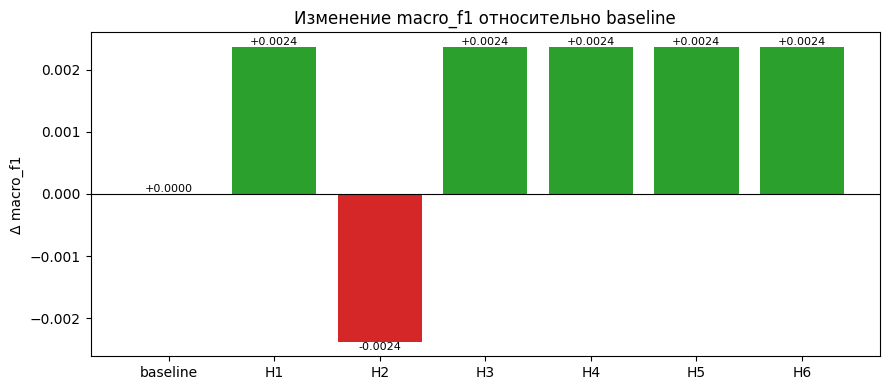

In [14]:
comparison = pd.DataFrame(experiments)
comparison['delta_primary'] = comparison[primary_metric] - baseline_metrics[primary_metric]

def make_conclusion(delta):
    if delta > 1e-9:
        return 'вырос'
    if delta < -1e-9:
        return 'ухудшился'
    return 'не изменился'

comparison['conclusion'] = comparison['delta_primary'].map(make_conclusion)
display(comparison.round(4))

# Изменение основной метрики относительно baseline по вариантам.
plt.figure(figsize=(9, 4))
colors = ['tab:green' if d > 1e-9 else ('tab:red' if d < -1e-9 else 'tab:gray')
          for d in comparison['delta_primary']]
plt.bar(comparison['experiment'], comparison['delta_primary'], color=colors)
plt.axhline(0.0, color='black', linewidth=0.8)
plt.title(f'Изменение {primary_metric} относительно baseline')
plt.ylabel(f'Δ {primary_metric}')
for i, d in enumerate(comparison['delta_primary']):
    plt.text(i, d, f'{d:+.4f}', ha='center',
             va='bottom' if d >= 0 else 'top', fontsize=8)
plt.tight_layout()
plt.savefig('delta_primary.png', dpi=120)
plt.show()

## 6. Выбор варианта и ограничения

Вариант выбираем по правилу из раздела 1: максимум macro-F1, при равенстве — максимум accuracy, при полном равенстве — более ранний вариант (baseline). Затем сравниваем исправленные и новые ошибки с baseline.

In [15]:
# Правило из раздела 1. При полном равенстве метрик stable-сортировка
# сохраняет более ранний вариант (baseline стоит первым).
best = comparison.sort_values(
    [primary_metric, tie_break_metric],
    ascending=False,
    kind='stable'
).iloc[0]
print('Лучший вариант по правилу раздела 1:', best['experiment'])

Лучший вариант по правилу раздела 1: H1


In [16]:
best_name = best['experiment']
best_score = best[primary_metric]
best_model = models[best_name]
best_predictions = predictions_by_name[best_name]

# Сравнение ошибок с baseline: какие исправлены, какие добавились.
err_view = pd.DataFrame({
    'image_id': val_df['image_id'].to_numpy(),
    'true': val_df['label'].to_numpy(),
    'baseline_pred': np.array(CLASS_NAMES)[baseline_predictions],
    'best_pred': np.array(CLASS_NAMES)[best_predictions],
})
fixed_errors = err_view[(err_view['true'] != err_view['baseline_pred'])
                        & (err_view['true'] == err_view['best_pred'])]
new_errors = err_view[(err_view['true'] == err_view['baseline_pred'])
                      & (err_view['true'] != err_view['best_pred'])]
print('Исправлено ошибок baseline:', len(fixed_errors), '| новых ошибок:', len(new_errors))
if len(fixed_errors):
    display(fixed_errors)
if len(new_errors):
    display(new_errors)
print('Выбран:', best_name, '| Основная метрика:', f'{best_score:.4f}')

Исправлено ошибок baseline: 1 | новых ошибок: 0


,image_id,true,baseline_pred,best_pred
419,Avocado Green 1/r1_44_100,unripe,overripe,unripe


Выбран: H1 | Основная метрика: 1.0000


**Вывод:** фактический ответ по каждой гипотезе даёт колонка conclusion в таблице раздела 5: гипотеза подтверждена, только если macro-F1 вырос. Если прироста нет, честно фиксируем неподтверждение и сохраняем baseline — это допустимый результат эксперимента. Выбранный вариант сохраняется в разделе 7 без повторного обучения и воспроизводится по predict.py.

Ограничения: (а) выбор сделан на validation из 459 изображений — различия в 1-2 ошибки статистически хрупки; (б) недетерминизм GPU даёт колебания метрик порядка тысячных, поэтому «улучшением» считаем только превышение, а не случайность; (в) test не использовался — итоговая проверка на нём остаётся за заданием 06.

## 7. Сохранение результата

Сохраняем таблицу экспериментов, выбранную модель, predict-функцию и протокол выбора.

In [17]:
result_dir = Path('experiment_results')
result_dir.mkdir(exist_ok=True)
comparison.to_csv(result_dir / 'experiments.csv', index=False, encoding='utf-8-sig')

# Выбранная модель (формат .keras, как в ноутбуке 03).
best_model.save(result_dir / 'final_model.keras')

# predict-функция: самостоятельный запуск без обучения.
predict_src = '''from pathlib import Path
import numpy as np
import tensorflow as tf
from PIL import Image

IMG_SIZE = (224, 224)
CLASS_NAMES = ["unripe", "ripe", "overripe"]

def predict_image(path, model_path=None):
    # Возвращает стадию зрелости и вероятности классов для одного изображения.
    if model_path is None:
        model_path = Path(__file__).parent / 'final_model.keras'
    model = tf.keras.models.load_model(model_path)
    image = np.asarray(Image.open(path).convert("RGB"))
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.expand_dims(image, 0)
    probs = model.predict(image, verbose=0)[0]
    idx = int(np.argmax(probs))
    return {"label": CLASS_NAMES[idx],
            "probability": float(probs[idx]),
            "probabilities": {n: float(p) for n, p in zip(CLASS_NAMES, probs)}}
'''
(result_dir / 'predict.py').write_text(predict_src, encoding='utf-8')

# Протокол выбора.
selection_lines = [
    f'selected: {best_name}',
    f'{primary_metric} = {best[primary_metric]:.6f}',
    f'{tie_break_metric} = {best[tie_break_metric]:.6f}',
    'rule: максимум macro_f1; при равенстве — максимум accuracy; при полном равенстве — более ранний вариант (baseline)',
    f'experiments: {", ".join(comparison["experiment"])}',
]
(result_dir / 'selection.txt').write_text('\n'.join(selection_lines), encoding='utf-8')

import shutil
shutil.copy('delta_primary.png', result_dir / 'delta_primary.png')
print('Сохранено в', result_dir, ':', sorted(p.name for p in result_dir.iterdir()))

Сохранено в experiment_results : ['delta_primary.png', 'experiments.csv', 'final_model.keras', 'predict.py', 'selection.txt']


### Повторная загрузка

Проверяем, что сохранённое решение после загрузки выдаёт те же ответы без повторного обучения. Вход — JPEG/PNG-изображение авокадо; выход — стадия зрелости и распределение вероятностей.

In [18]:
# Загружаем сохранённое решение без повторного обучения.
reloaded = tf.keras.models.load_model(result_dir / 'final_model.keras')
reload_predictions = reloaded.predict(val_ds, verbose=0).argmax(axis=1)
assert np.array_equal(reload_predictions, best_predictions), 'Предсказания после загрузки не совпадают!'
print('Предсказания загруженной модели совпадают с исходными на всей validation.')

# Ответ по одному PNG: первое изображение validation сохраняем как PNG и предсказываем.
import importlib.util
spec = importlib.util.spec_from_file_location('predict', result_dir / 'predict.py')
predict = importlib.util.module_from_spec(spec)
spec.loader.exec_module(predict)

sample_row = val_df.iloc[0]
sample_png = Path('sample_check.png')
Image.open(sample_row['path']).convert('RGB').save(sample_png)
result = predict.predict_image(sample_png)
print(f"{sample_row['image_id']}: истина={sample_row['label']}, "
      f"предсказано={result['label']} (вероятность={result['probability']:.3f})")
assert result['label'] == CLASS_NAMES[best_predictions[0]], 'Ответ по PNG не совпал'
print('Проверка по одному PNG пройдена.')

Предсказания загруженной модели совпадают с исходными на всей validation.
Avocado 2/294_100: истина=ripe, предсказано=ripe (вероятность=1.000)
Проверка по одному PNG пройдена.
